In [2]:
# Install required libraries
!pip install -q openpyxl pyarrow scikit-learn pandas numpy

import os
from urllib.parse import urlparse

import numpy as npy
import pandas as pda
from google.colab import files
from sklearn.model_selection import train_test_split


In [5]:
# 1. Upload Dataset into Google Colab

print("Upload 'cybersecurity.xlsx':")
uploaded = files.upload()
input_path = list(uploaded.keys())[0]

Upload 'cybersecurity.xlsx':


Saving cybersecurity.xlsx to cybersecurity.xlsx


In [6]:
# 2. Helper Functions
def bin_port(port: int) -> str:
    """Group Layer 4 ports into standard IANA functional ranges."""
    if port <= 1023:
        return "system"
    elif port <= 49151:
        return "registered"
    return "ephemeral"


def extract_url_path(url_value: str) -> str:
    """Strip random query IDs (e.g., ?id=12345) and isolate clean endpoint paths."""
    if url_value == "No_URL":
        return "none"
    parsed = urlparse(url_value)
    return parsed.path.lower() if parsed.path else "root"

In [7]:
# 3. Run Curation & Feature Engineering Pipeline

output_dir = "/Milestone1/curated_data"
os.makedirs(output_dir, exist_ok=True)

# Load Workbook & Verify Schema
xls = pda.ExcelFile(input_path)
print(f"Sheets found: {xls.sheet_names}")
df = pda.read_excel(input_path, sheet_name="cybersecurity")

assert df.shape == (10000, 13), f"Unexpected shape: {df.shape}"
assert df["src_port"].between(0, 65535).all(), "Invalid src_port values found."
assert df["dst_port"].between(0, 65535).all(), "Invalid dst_port values found."
assert (df["bytes_sent"] >= 0).all() and (
    df["bytes_received"] >= 0
).all(), "Negative byte counts found."
# Duplicate Audit & Missing Value Imputation
dup_count = df.duplicated().sum()
print(f"Exact duplicates found: {dup_count}")
df = df.drop_duplicates().copy()

# Impute 3,232 missing URLs and create binary indicator
df["has_url"] = df["url"].notnull().astype(int)
df["url"] = df["url"].fillna("No_URL")

# Temporal Extraction
df["timestamp"] = pda.to_datetime(df["timestamp"])
df["hour_of_day"] = df["timestamp"].dt.hour
df["is_weekend"] = (df["timestamp"].dt.dayofweek >= 5).astype(int)

# IANA Port Range Binning
df["src_port_bin"] = df["src_port"].apply(bin_port)
df["dst_port_bin"] = df["dst_port"].apply(bin_port)

# Clean URL Endpoint Extraction
df["url_path"] = df["url"].apply(extract_url_path)

# Log Transformations & Directional Byte Ratios
df["log_bytes_sent"] = npy.log1p(df["bytes_sent"])
df["log_bytes_received"] = npy.log1p(df["bytes_received"])
df["log_total_bytes"] = npy.log1p(df["bytes_sent"] + df["bytes_received"])
df["byte_ratio"] = df["log_bytes_sent"] - df["log_bytes_received"]

# Boolean to Integer
df["is_internal_traffic"] = df["is_internal_traffic"].astype(int)

# Drop 100% Unique / Leakage-Prone Identifiers (src_ip, dst_ip, raw timestamp, raw url)
drop_cols = ["timestamp", "src_ip", "dst_ip", "url"]
df_clean = df.drop(columns=drop_cols)

# One-Hot Encode Categorical Predictors
cat_cols = ["protocol", "user_agent", "src_port_bin", "dst_port_bin", "url_path"]
df_encoded = pda.get_dummies(df_clean, columns=cat_cols, drop_first=False, dtype=int)

print(f"Curated & encoded dataset shape: {df_encoded.shape}")



Sheets found: ['cybersecurity']
Exact duplicates found: 0
Curated & encoded dataset shape: (10000, 51)


In [11]:

parquet_path = os.path.join(output_dir, "curated_threat_data.parquet")
df_encoded.to_parquet(parquet_path, index=False)
print(f"[INFO] Saved curated dataset to: {parquet_path}")

# 4. Stratified 80/20 Train/Test Split & Export

X = df_encoded.drop(columns=["label", "attack_type"])
y = df_encoded["attack_type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Save artifacts in Colab workspace
parquet_path = os.path.join(output_dir, "curated_threat_data.parquet")
df_encoded.to_parquet(parquet_path, index=False)

X_train.to_parquet(os.path.join(output_dir, "X_train.parquet"), index=False)
X_test.to_parquet(os.path.join(output_dir, "X_test.parquet"), index=False)
y_train.to_frame().to_parquet(
    os.path.join(output_dir, "y_train.parquet"), index=False
)
y_test.to_frame().to_parquet(
    os.path.join(output_dir, "y_test.parquet"), index=False
)

print(
    f"[INFO] Train split: {X_train.shape} | Test split: {X_test.shape}"
)
print("\n[INFO] Stratified Test Set Class Distribution:")
print(y_test.value_counts())

[INFO] Saved curated dataset to: /Milestone1/curated_data/curated_threat_data.parquet
[INFO] Train split: (8000, 49) | Test split: (2000, 49)

[INFO] Stratified Test Set Class Distribution:
attack_type
benign                 1920
brute-force              22
port-scan                16
sql-injection            13
xss                       7
credential-stuffing       6
command-injection         5
ddos                      5
exploit-attempt           4
c2                        2
Name: count, dtype: int64


In [12]:
# Milestone 2: Analytic Methods + MITRE ATT&CK Mapping
!pip install -q shap

import shap
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, f1_score, roc_auc_score

In [16]:
# 1. MITRE ATT&CK Mapping Dictionary
MITRE_MAPPING = {
    "benign": ("None", "Benign Baseline Traffic"),
    "port-scan": ("Reconnaissance / Discovery (TA0043 / TA0007)", "Active Scanning: Port Scanning (T1595.001)"),
    "brute-force": ("Credential Access (TA0006)", "Brute Force: Password Guessing (T1110.001)"),
    "credential-stuffing": ("Credential Access (TA0006)", "Brute Force: Credential Stuffing (T1110.004)"),
    "sql-injection": ("Initial Access (TA0001)", "Exploit Public-Facing Application (T1190)"),
    "xss": ("Initial Access / Execution (TA0001 / TA0002)", "Exploit Public-Facing Application (T1190)"),
    "command-injection": ("Execution (TA0002)", "Command and Scripting Interpreter (T1059)"),
    "exploit-attempt": ("Execution / Lateral Movement (TA0002 / TA0008)", "Exploitation of Remote Services (T1210)"),
    "ddos": ("Impact (TA0040)", "Network Denial of Service (T1498)"),
    "c2": ("Command and Control (TA0011)", "Application Layer Protocol (T1071.001)"),
}

In [13]:
# 2. Track A: 10-Class Classification (attack_type)
lr_baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])
lr_baseline.fit(X_train, y_train)
pred_lr = lr_baseline.predict(X_test)
print(f"[10-Class] Logistic Regression Macro F1: {f1_score(y_test, pred_lr, average='macro'):.4f}")

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)
print(f"[10-Class] Random Forest Macro F1:       {f1_score(y_test, pred_rf, average='macro'):.4f}")
print("\n=== 10-Class Random Forest Report ===")
print(classification_report(y_test, pred_rf, zero_division=0))

[10-Class] Logistic Regression Macro F1: 0.1574
[10-Class] Random Forest Macro F1:       0.1890

=== 10-Class Random Forest Report ===
                     precision    recall  f1-score   support

             benign       0.97      1.00      0.98      1920
        brute-force       0.44      0.18      0.26        22
                 c2       0.00      0.00      0.00         2
  command-injection       0.00      0.00      0.00         5
credential-stuffing       0.00      0.00      0.00         6
               ddos       0.50      0.60      0.55         5
    exploit-attempt       0.00      0.00      0.00         4
          port-scan       0.33      0.06      0.11        16
      sql-injection       0.00      0.00      0.00        13
                xss       0.00      0.00      0.00         7

           accuracy                           0.96      2000
          macro avg       0.22      0.18      0.19      2000
       weighted avg       0.94      0.96      0.95      2000



In [14]:
# 3. Track B: Stage-1 Binary Threat Detection (label: 0=Benign, 1=Attack)
y_bin = df_encoded["label"]
X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(
    X, y_bin, test_size=0.20, random_state=42, stratify=y_bin
)

rf_bin = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
rf_bin.fit(X_tr_b, y_tr_b)
probs_rf_b = rf_bin.predict_proba(X_te_b)[:, 1]
pred_rf_b = (probs_rf_b >= 0.35).astype(int)  # Calibrated threshold (t=0.35)

cv_auc = cross_val_score(rf_bin, X, y_bin, cv=5, scoring="roc_auc").mean()
print(f"\n=== Stage-1 Binary Detection (Threshold = 0.35) ===")
print(f"5-Fold CV ROC-AUC: {cv_auc:.4f} | Holdout ROC-AUC: {roc_auc_score(y_te_b, probs_rf_b):.4f}")
print(classification_report(y_te_b, pred_rf_b, zero_division=0))


=== Stage-1 Binary Detection (Threshold = 0.35) ===
5-Fold CV ROC-AUC: 0.8846 | Holdout ROC-AUC: 0.8371
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1920
           1       0.41      0.47      0.44        80

    accuracy                           0.95      2000
   macro avg       0.70      0.72      0.71      2000
weighted avg       0.96      0.95      0.95      2000



In [17]:
# 4. Attach MITRE ATT&CK Tactics & Techniques to 10-Class Predictions
mapped_alerts = pda.DataFrame({
    "actual_attack": y_test.values,
    "predicted_attack": pred_rf,
})
mapped_alerts["mitre_tactic"] = mapped_alerts["predicted_attack"].map(lambda k: MITRE_MAPPING[k][0])
mapped_alerts["mitre_technique"] = mapped_alerts["predicted_attack"].map(lambda k: MITRE_MAPPING[k][1])

print("\n=== Sample MITRE ATT&CK Mapped Alerts ===")
print(mapped_alerts[mapped_alerts["predicted_attack"] != "benign"].head(10))


=== Sample MITRE ATT&CK Mapped Alerts ===
            actual_attack predicted_attack  \
109           brute-force        port-scan   
169                benign             ddos   
178                benign        port-scan   
286   credential-stuffing      brute-force   
385                benign      brute-force   
454                  ddos             ddos   
696     command-injection              xss   
740                  ddos             ddos   
1054          brute-force      brute-force   
1079                 ddos             ddos   

                                      mitre_tactic  \
109   Reconnaissance / Discovery (TA0043 / TA0007)   
169                                Impact (TA0040)   
178   Reconnaissance / Discovery (TA0043 / TA0007)   
286                     Credential Access (TA0006)   
385                     Credential Access (TA0006)   
454                                Impact (TA0040)   
696   Initial Access / Execution (TA0001 / TA0002)   
740               

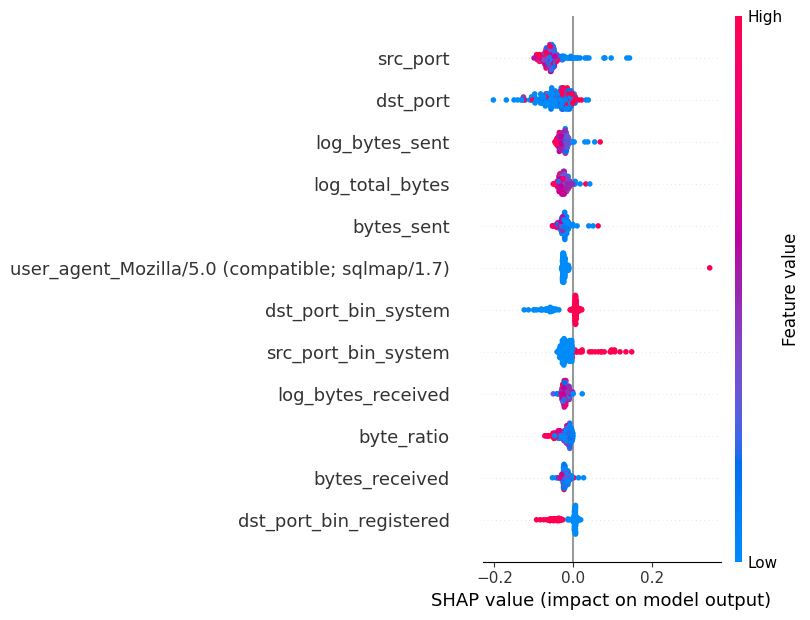

In [18]:
# 5. TreeSHAP Feature Attribution Summary (Stage-1 Binary RF)
explainer = shap.TreeExplainer(rf_bin)
shap_values = explainer.shap_values(X_te_b.iloc[:200])
# Handle shap output shape across versions (list of arrays vs 3D array)
sv_attack = shap_values[1] if isinstance(shap_values, list) else shap_values[:, :, 1]
shap.summary_plot(sv_attack, X_te_b.iloc[:200], max_display=12)